# 01 — Explore sub-001 (Makin et al. 2012, OpenNeuro ds004347)

**Purpose.** First exploration of one subject of **Makin et al. (2012),
Experiment 1** — EEG of **symmetry perception**: 80 reflection vs. 80
random black-and-white patterns, with the sustained posterior negativity
(SPN) measured over the ROI **PO7/PO8** (Makin et al. 2012, OpenNeuro
**ds004347**, local BIDS root `data/on004347`).  One subject (sub-001) is
inspected end to end: recording metadata, event structure, a raw-data
plot with events marked (M2 deliverable), a PSD to document line noise
and drift, and a first statistical look at candidate bad channels.

The BIDS task label `jacobsen` is just the dataset's internal name; the
experiment follows Makin et al. (2012), not Jacobsen (2006).

**Dataset / download.** The data come from the public **OpenNeuro S3
mirror** (ds004347 = NEMAR on004347) via our standard-library downloader —
`mne-bids` is only used for *reading* the BIDS dataset afterwards:

```bash
python -m src.download --subjects 001   # -> data/on004347, sub-001 only
```

It is *not* run here — the notebook assumes the data are already on disk.


In [1]:
import warnings

import mne

# Keep MNE output quiet (its verbose INFO logs print absolute machine paths).
mne.set_log_level("WARNING")

# The only warnings filtered in this notebook are the known, documented
# mne-bids sidecar warnings.  They come from the quoted channel names in
# channels.tsv / electrodes.tsv ("...channels.tsv sidecar...", "DigMontage is
# only a subset...", ...) and from the EXG channels having no sidecar
# positions; all of them are handled in src/io.py (channel types and montage
# re-applied by hand, see the io.py module docstring), so nothing is
# actionable here.
warnings.filterwarnings("ignore", message=".*channels.tsv sidecar.*")
warnings.filterwarnings("ignore", message=".*Cannot set channel type.*")
warnings.filterwarnings("ignore", message=".*No fiducial points found for ctf_head.*")
warnings.filterwarnings("ignore", message=".*There are channels without locations.*")
warnings.filterwarnings("ignore", message=".*DigMontage is only a subset.*")
warnings.filterwarnings("ignore", message=".*Unable to map the following column.*")

import sys
from pathlib import Path

# Make `src` importable from notebooks/.
sys.path.append(str(Path.cwd().resolve().parent))


## Load sub-001 and recording metadata

`src.io.load_raw` wraps `read_raw_bids` and fixes the known dataset
issues (quoted channel names in `channels.tsv`, EXG1-8 typed `eog`,
BDF `Status` trigger channel dropped, `biosemi64` montage).

In [2]:
import src.io

raw = src.io.load_raw('001', preload=True)
raw.info

sfreq = raw.info['sfreq']
duration = raw.n_times / sfreq
print(f'sfreq          : {sfreq} Hz')
print(f'duration       : {duration:.1f} s = {duration / 60:.1f} min')

from collections import Counter
type_counts = Counter(t for t in raw.get_channel_types() if t != 'stab')
print('channel types  :', dict(sorted(type_counts.items())))

import json
eeg_json = json.loads(Path(f"{src.io.BIDS_ROOT}/sub-001/eeg/sub-001_task-{src.io.TASK}_eeg.json").read_text(encoding='utf-8'))
print('EEGReference        :', eeg_json['EEGReference'])
print('PowerLineFrequency  :', eeg_json['PowerLineFrequency'], 'Hz')
print('HardwareFilters     :', eeg_json.get('HardwareFilters'))
print('-> reference is CMS/DRL (active electrodes, BioSemi), NOT a mastoid/ear reference;')
print('   an average or linked-mastoid re-reference is needed before ERP comparison -> M3.')
print('-> PowerLineFrequency is 50 Hz (UK mains), and there is no hardware high-pass.')

sfreq          : 512.0 Hz
duration       : 1039.0 s = 17.3 min
channel types  : {'eeg': 64, 'eog': 8}
EEGReference        : CMS/DRL
PowerLineFrequency  : 50 Hz
HardwareFilters     : n/a
-> reference is CMS/DRL (active electrodes, BioSemi), NOT a mastoid/ear reference;
   an average or linked-mastoid re-reference is needed before ERP comparison -> M3.
-> PowerLineFrequency is 50 Hz (UK mains), and there is no hardware high-pass.


## Events per condition and inter-trial intervals

Stimulus codes: `1` = reflection, `3` = random (from `events.json`);
`255` marks block starts and is ignored.  Onsets are read as **seconds**
even though `events.json` claims the unit is `ms` — another dataset
inconsistency documented in `src/io.py`.

In [3]:
import numpy as np
events, event_id = src.io.get_events(raw)
print('event_id       :', event_id)

counts = {name: int((events[:, 2] == code).sum()) for name, code in event_id.items()}
print('event counts   :', counts)
print('total          :', len(events))

# Inter-trial interval (onset-to-onset across both conditions).
onsets = events[:, 0] / sfreq
isi = np.diff(onsets)
print(f'ITI (onset-to-onset): mean {isi.mean():.3f} s, std {isi.std():.3f} s, '
      f'min {isi.min():.3f} s, max {isi.max():.3f} s')
print(f'ITI quantiles (25/50/75%): {np.percentile(isi, [25, 50, 75]).round(3)}')

event_id       : {'reflection': 1, 'random': 3}
event counts   : {'reflection': 80, 'random': 79}
total          : 159
ITI (onset-to-onset): mean 6.387 s, std 2.301 s, min 5.170 s, max 32.301 s
ITI quantiles (25/50/75%): [5.631 6.007 6.43 ]


## Raw data with events, and PSD

`sub-001_raw_events.png` shows **20 s of posterior EEG** (all EEG channels
starting with P/PO/O, plus Iz — i.e. P*, PO*, O*, Iz; PO7 and PO8 included,
no frontal channels) with the stimulus events marked and labelled
**reflection / random**:

- `picks=posterior` keeps the analysis ROI on top and the frontal blink
  artifacts out of the slide figure.
- `highpass=0.1` is a **display-only** high-pass passed to `raw.plot`: the
  BioSemi recording has no hardware high-pass, so slow drift (hundreds of µV)
  pushes traces diagonally through neighbouring rows.  The 0.1 Hz filter
  cleans up the *drawing* — the underlying `Raw` object stays unfiltered
  (filtering decisions are made in M3) — and is low enough to leave the SPN
  window (300–1000 ms) untouched.

Also saved: `sub-001_psd.png` (line noise and drift).  The M2 deliverables
land in `docs/figures/`.


saved: docs\figures\sub-001_raw_events.png
saved: docs\figures\sub-001_psd.png


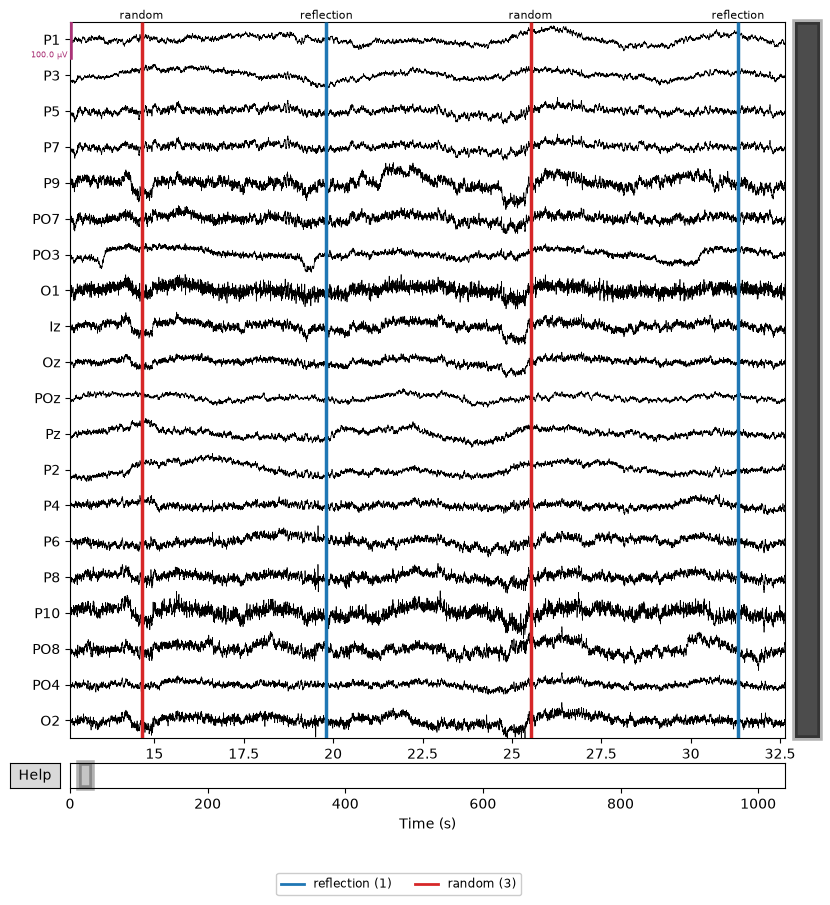

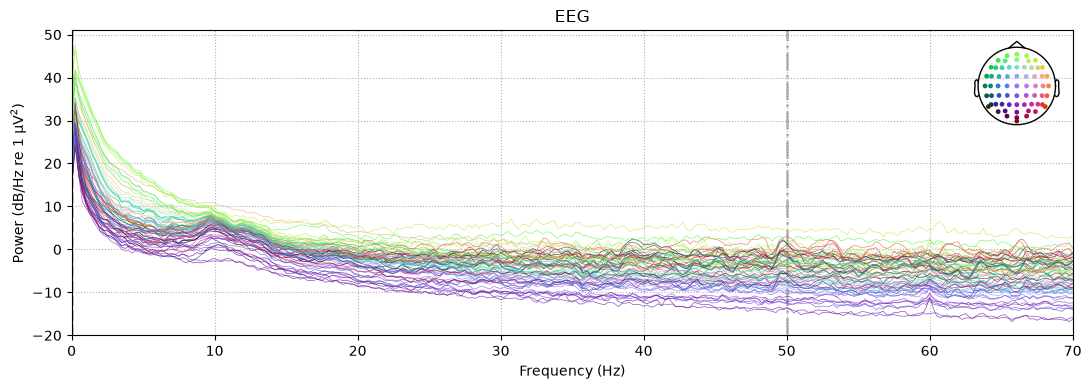

In [4]:
import src.plotting
from pathlib import Path

FIG = Path('..') / 'docs' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

# Posterior ROI view for the slide: P*/PO*/O*/Iz (PO7 + PO8 included, none frontal).
posterior = [n for n, t in zip(raw.ch_names, raw.get_channel_types())
             if t == 'eeg' and (n.startswith('P') or n.startswith('O') or n == 'Iz')]
assert {'PO7', 'PO8'} <= set(posterior), posterior

fig = src.plotting.plot_raw_with_events(
    raw, events, event_id,
    picks=posterior,
    duration=20,
    fname=FIG / 'sub-001_raw_events.png',
)
psd_fig = src.plotting.plot_psd(raw, fmax=70, fname=FIG / 'sub-001_psd.png')

# Figure paths relative to the repo root (no machine-specific absolute paths).
repo_root = Path.cwd().resolve().parent
for name in ('sub-001_raw_events.png', 'sub-001_psd.png'):
    print('saved:', (FIG / name).resolve().relative_to(repo_root))


## Per-channel variability and candidate bad channels

**Why the 1–40 Hz copy?** The BioSemi recording has no hardware high-pass, so
its per-channel std on the raw data is dominated by the DC offset and slow
drift of each electrode (median raw std was ~508 µV — pure drift, data quality
invisible in it). A channel therefore ranked as "bad" on raw std was really
just the channel that drifted the most, not the noisiest one.

So this check runs on a **copy** of the EEG, band-passed to **1–40 Hz**
(`raw.copy().pick('eeg').filter(1, 40)`) — the copy exists only for this
diagnostic; the original raw data is untouched (filtering choices are made in
M3). We compute the per-channel std in µV and a **two-sided robust z-score**
against the median across channels:

z = (std − median) / (1.4826 · MAD), flagged when |z| > 3

(two-sided, because *low* std — a flat, high-impedance contact — is just as
suspicious as high std).

In [5]:
raw_1_40 = raw.copy().pick('eeg').filter(1, 40, verbose=False)
X = raw_1_40.get_data() * 1e6  # µV
stds = X.std(axis=1)
names = raw_1_40.ch_names

med = np.median(stds)
mad = np.median(np.abs(stds - med))
z = (stds - med) / (1.4826 * mad)
flag_idx = np.where(np.abs(z) > 3)[0]

print(f'1-40 Hz copy, per-channel std: median {med:.2f} µV, MAD {mad:.2f} µV')
for name in ('PO7', 'PO8', 'PO3'):
    i = names.index(name)
    print(f'  {name}: std {stds[i]:.2f} µV, robust z {z[i]:+.2f}')

flagged = [(names[i], round(float(stds[i]), 2), round(float(z[i]), 2)) for i in flag_idx]
print(f'flagged channels (|z| > 3): {len(flagged)}')
for name, s, zz in flagged:
    print(f'  {name}: std {s:.2f} µV, z {zz:+.2f}')

# --- PO3 in numbers ----------------------------------------------------------
# (a) fast (1-40 Hz) variance, (b) unfiltered slow drift, (c) correlation
# with its neighbours on the 1-40 Hz copy.

# (a) rank of PO3 in the 1-40 Hz std distribution.
i3 = names.index('PO3')
order = np.argsort(stds)
rank = int(np.where(order == i3)[0][0]) + 1
lowest = [(names[j], round(float(stds[j]), 2)) for j in order[:5]]
print(f'(a) PO3 std on 1-40 Hz copy: {stds[i3]:.2f} µV '
      f'({stds[i3] / med * 100:.0f}% of the median {med:.2f} µV), '
      f'rank {rank}/{len(stds)} lowest; 5 lowest: {lowest}')

# (b) slow drift of the UNFILTERED signal: peak-to-peak plus the span of a
#     linear trend, for PO3 vs the median across all EEG channels.
X_raw = raw.copy().pick('eeg').get_data() * 1e6
t = np.arange(X_raw.shape[1]) / sfreq
t_c = t - t.mean()
trend_range = np.abs((X_raw * t_c).sum(1) / (t_c ** 2).sum()) * t.max()
p2p = np.ptp(X_raw, axis=1)
print(f'(b) unfiltered slow drift  : PO3 peak-to-peak {p2p[i3]:.0f} µV vs median '
      f'{np.median(p2p):.0f} µV linear-trend range {trend_range[i3]:.0f} µV vs median '
      f'{np.median(trend_range):.0f} µV')

# Diagonal trace in the old (unfiltered, first-30-channel, first-20-s) plot:
# which channel ran diagonally?
sf = raw.info['sfreq']
w_start = max(events[0, 0] / sf - 2.0, 0.0)
i0, i1 = int(w_start * sf), int((w_start + 20.0) * sf)
W = X_raw[:30, i0:i1]
tt = np.linspace(0, 1, W.shape[1])
tt -= tt.mean()
sl = np.abs((W * tt).sum(1) / (tt ** 2).sum()) * (tt.max() - tt.min())  # trend span over the window
top = np.argsort(sl)[::-1][:3]
print(f'old plot window, largest linear-trend span: '
      + ', '.join(f'{names[j]} {sl[j]:.0f} µV' for j in top))

# (c) correlation with its neighbours on the 1-40 Hz copy.
corr = {n: float(np.corrcoef(X[i3], X[names.index(n)])[0, 1]) for n in ('PO7', 'POz', 'O1', 'P3')}
print('(c) 1-40 Hz correlation PO3 with neighbours: '
      + ', '.join(f'{k} {v:.2f}' for k, v in corr.items()))
all_corr = np.corrcoef(X)[np.triu_indices(len(X), 1)]
print(f'    (median over all channel pairs: {float(np.median(all_corr)):.2f})')

# Verdict, driven only by the numbers above:
low_fast_var = stds[i3] < 0.5 * med
big_drift = p2p[i3] > 1.5 * np.median(p2p)
weak_coupling = any(r < 0.3 for r in corr.values())
print(f'low fast variance: {low_fast_var}; large drift: {big_drift}; '
      f'weak neighbour coupling (<0.3 with POz): {weak_coupling}')
if (low_fast_var and (big_drift or weak_coupling)):
    print('PO3 = candidate bad channel (likely poor contact), '
          'to be confirmed with pyprep/RANSAC in M3')


1-40 Hz copy, per-channel std: median 12.08 µV, MAD 4.20 µV
  PO7: std 10.15 µV, robust z -0.31
  PO8: std 16.33 µV, robust z +0.68
  PO3: std 5.54 µV, robust z -1.05
flagged channels (|z| > 3): 10
  Fp1: std 68.34 µV, z +9.04
  AF7: std 47.27 µV, z +5.65
  AF3: std 40.83 µV, z +4.62
  Fpz: std 73.94 µV, z +9.94
  Fp2: std 64.73 µV, z +8.46
  AF8: std 59.39 µV, z +7.60
  AF4: std 43.63 µV, z +5.07
  AFz: std 35.96 µV, z +3.84
  F8: std 35.74 µV, z +3.80
  FC6: std 38.86 µV, z +4.30
(a) PO3 std on 1-40 Hz copy: 5.54 µV (46% of the median 12.08 µV), rank 4/64 lowest; 5 lowest: [('P2', 5.19), ('P1', 5.19), ('POz', 5.29), ('PO3', 5.54), ('Oz', 6.08)]


(b) unfiltered slow drift  : PO3 peak-to-peak 4199 µV vs median 2267 µV linear-trend range 2461 µV vs median 1520 µV
old plot window, largest linear-trend span: PO3 1025 µV, POz 300 µV, AF3 153 µV
(c) 1-40 Hz correlation PO3 with neighbours: PO7 0.63, POz 0.17, O1 0.66, P3 0.45
    (median over all channel pairs: 0.37)
low fast variance: True; large drift: True; weak neighbour coupling (<0.3 with POz): True
PO3 = candidate bad channel (likely poor contact), to be confirmed with pyprep/RANSAC in M3


### PO3 — quantified check (numbers, not impressions)

Three measurements for PO3, computed on the outputs above:

- **(a) Fast variance**: per-channel std on the 1–40 Hz copy,
  relative to the median across all EEG channels.
- **(b) Slow drift**: peak-to-peak and linear-trend range of the
  **unfiltered** signal, compared with the median channel.  This also
  answers which channel drew the diagonal trace through the old
  unfiltered raw plot (first 30 channels, first 20 s).
- **(c) Neighbour coupling**: 1–40 Hz correlation with PO7, POz, O1 and P3
  (an intact electrode keeps close phase with its neighbours).


## Observations & open doubts

### Observations (from the actual outputs above and the saved figures)

- **Recording**: 512 Hz, ~1039 s (~17.3 min); 64 EEG + 8 EOG (EXG1-8) channels.
- **Reference**: `EEGReference: CMS/DRL` (BioSemi active electrodes) — not a
  mastoid reference, so an average (or linked-mastoid) re-reference is needed
  before ERP comparison (-> M3). `PowerLineFrequency: 50` Hz, no hardware filters.
- **Events**: 160 stimulus trials expected from the design, but only **159 found**
  (80 reflection, 79 random) — exactly one random trial is missing from
  `events.tsv`. To be confirmed against the BDF `Status` channel in M3.
- **Inter-trial interval**: onset-to-onset mean 6.39 s, SD 2.30 s, min 5.17 s,
  max 32.30 s (median 6.01 s). These mean and SD statistics include the
  pauses between blocks (max 32.3 s), so they are not the design's trial
  duration. The 32 s max is the pause between blocks or a
  skipped trial — worth re-checking when the missing random trial is investigated.
- **Slide figure (`sub-001_raw_events.png`)**: 20 s of posterior EEG
  (P*/PO*/O*/Iz — PO7 and PO8 visible, nothing frontal) with reflection/random
  events marked and labelled in clearly different colours. The 0.1 Hz
  **display-only** high-pass removes the slow drift from the drawing (the data
  itself stays untouched), so no trace runs diagonally through other rows any
  more.
- **Blinks/ocular artifacts**: large frontal deflections on **Fp1/AF7** (and less
  on Fp2/AF8) in the raw data — classic blink/VEOG pattern. ICA in M3.
- **Slow drift**: strong low-frequency drift throughout (no hardware high-pass).
  On the **raw** std this drift dominates completely (median ~508 µV), which is
  why the bad-channel scan runs on the 1–40 Hz copy instead.
- **Candidate bad channels** (1–40 Hz copy, robust z on std, |z| > 3): median
  std **12.08 µV**, MAD 4.20 µV. The **10 flagged channels are all frontal or
  fronto-lateral** — Fp1, Fp2, Fpz, AF3, AFz, AF4, AF7, AF8, F8, FC6. Their huge
  stds (36–74 µV) are **blinks**, not bad electrodes (see the Fp1/AF7 look in the
  raw data), so this is exactly the artifact ICA will remove in M3 — they are
  **not** manually marked as bad channels.
- **PO7 is fine**: std 10.15 µV, robust z −0.31 — comfortably inside the
  distribution, and one of our two analysis channels. The earlier impression
  that PO7 was bad came entirely from its raw-data drift once the DC/drift
  dominance was removed.
- **PO8**: std 16.33 µV, z +0.68 — slightly noisy but well within the spread.
- **PO3 = candidate bad channel (likely poor contact), to be confirmed with
  pyprep/RANSAC in M3.** The numbers: (a) std **5.54 µV** on the 1–40 Hz copy —
  ~46 % of the median 12.08 µV, among the lowest channels of all (rank 4/64;
  P2 5.19, P1 5.19, POz 5.29 µV are comparable); (b) **large slow drift** in the
  unfiltered signal — peak-to-peak **4199 µV vs a median of 2267 µV** (linear-
  trend range 2461 µV vs 1520 µV); and in the old unfiltered 20 s plot window
  PO3's linear trend spans **~1025 µV vs ~300 µV for the next channel** — the
  diagonal trace was **PO3**, not PO7; (c) weak coupling with one neighbour —
  1–40 Hz correlation is **0.17 with POz** (PO7 0.63, O1 0.66, P3 0.45;
  median over all channel pairs 0.37). Low fast variance plus large drift, as
  expected from a high-impedance contact; automatic detection (pyprep/RANSAC)
  decides in M3.
- **PSD**: clear alpha peak at **~10 Hz**; only a **tiny 50 Hz** line peak, so a
  notch filter is probably unnecessary (decided from the data, not by default)
  and a **small but visible 60 Hz peak** in some channels, which makes the notch
  question genuinely open.

### Open doubts about the dataset

1. **Quoted channel names** in `channels.tsv` (`'Fp1'` with literal quotes) —
   worked around in `src/io.py` (types and montage re-applied by hand).
2. **EXG1-8 all labelled EOG** in `channels.tsv`, but the paper recorded facial
   **EMG** (zygomaticus, corrugator) as well; no per-channel mapping is given.
   Which EXG channel is HEOG/VEOG/EMG is unknown (TODO in `src/io.py`).
3. `events.json` says onsets are in **"ms"**, but the actual onsets in
   `events.tsv` are in **seconds** — mne-bids reads them as seconds (correct).
4. The **60 Hz peak in a few channels** is unexpected for a UK lab (mains is
   50 Hz) — possibly an American-made piece of equipment or an aliasing
   artifact; open question to raise on the course forum (OpenNeuro ds004347).
